# RoundaboutHD: annotation coverage and camera comparison

**Questions:** How do annotated observations differ across cameras? How complete and consistent are the annotation records? For the same vehicles, does annotated frame time differ across cameras?

This notebook is the final analysis. `analysis.ipynb` preserves the original exploration, including superseded claims. All counts below are recomputed from source annotations. The four cameras observe different roundabouts; counts are not assumed to represent all road traffic.

**Cloud workflow:** Open in Google Colab and run all cells. Only selected annotation files are retrieved using HTTP byte ranges. No videos, full 8 GB download, Drive mount, or download to your computer is required. If `/content/RoundaboutHD.zip` already exists, it is reused. If the server stops supporting ranges, acquisition fails explicitly rather than downloading the entire archive.

Sources: [dataset](https://researchdata.bath.ac.uk/1574/), [documentation](https://github.com/siri-rouser/RoundaboutHD), [paper](https://arxiv.org/html/2507.08729v2), [association script](https://github.com/siri-rouser/multi_camera_tracking_labelling_tool/blob/main/MCVT_data_creation.py).

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import io
import json
import platform
import re
import sys
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare
from IPython.display import display, Markdown

FPS = 15
CAMERAS = [1, 2, 3, 4]
FIRST_FRAME, LAST_FRAME = 1, 9000
IS_COLAB = 'google.colab' in sys.modules
ROOT = Path('/content/analysis_results/final') if IS_COLAB else Path.cwd()
CACHE = Path('/content/roundabouthd_annotations') if IS_COLAB else ROOT / 'data' / 'raw'
TABLES, FIGURES, REPORTS = [ROOT / name for name in ['results', 'figures', 'reports']]
for directory in [CACHE, TABLES, FIGURES, REPORTS]:
    directory.mkdir(parents=True, exist_ok=True)

URL = 'https://researchdata.bath.ac.uk/1574/1/RoundaboutHD.zip'
ARCHIVE_PATH = Path('/content/RoundaboutHD.zip')
KEY = ['camera_id', 'vehicle_id', 'frame']
MC_COLUMNS = KEY + ['x', 'y', 'width', 'height', 'xworld', 'yworld']
SCT_COLUMNS = ['frame', 'local_id', 'xmin', 'ymin', 'xmax', 'ymax', 'class_id']
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'svg.hashsalt': 'roundabouthd'})

## 1. Retrieve annotation files and record provenance

The real archive uses `Multi_CAM_Ground_Turth.txt` and `imagesc00x/SCT/SCT_GT.txt`; some documentation spells these differently. File selection must succeed uniquely. Missing files are errors, not zero observations. Cached inputs are checked against their saved SHA-256 hashes.

In [2]:
class HTTPRangeReader(io.RawIOBase):
    def __init__(self, url):
        self.url, self.position, self.transferred = url, 0, 0
        with urllib.request.urlopen(urllib.request.Request(url, headers={'Range': 'bytes=0-0', 'Accept-Encoding': 'identity'}), timeout=60) as r:
            match = re.fullmatch(r'bytes 0-0/(\d+)', r.headers.get('Content-Range', ''))
            if r.status != 206 or not match:
                raise OSError('Server does not support the required byte ranges; no full download attempted.')
            self.length = int(match[1])
            r.read(1)
    def seekable(self): return True
    def readable(self): return True
    def tell(self): return self.position
    def seek(self, offset, whence=0):
        position = offset if whence == 0 else self.position + offset if whence == 1 else self.length + offset
        if position < 0: raise ValueError('Negative seek')
        self.position = position
        return position
    def read(self, size=-1):
        size = max(0, self.length - self.position) if size < 0 else min(size, max(0, self.length - self.position))
        if not size: return b''
        if size > 16 * 1024**2: raise ValueError('Refusing a large range read')
        start, end = self.position, self.position + size - 1
        req = urllib.request.Request(self.url, headers={'Range': f'bytes={start}-{end}', 'Accept-Encoding': 'identity'})
        with urllib.request.urlopen(req, timeout=90) as r:
            if r.status != 206 or r.headers.get('Content-Range') != f'bytes {start}-{end}/{self.length}':
                raise OSError('Incorrect range response; refusing to read archive body')
            result = r.read(size + 1)
        if len(result) != size: raise OSError('Truncated range response')
        self.position += size
        self.transferred += size
        return result



def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

manifest_path = CACHE / 'source_manifest.json'
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    for item in manifest['files']:
        path = CACHE / item['member']
        if not path.is_file() or sha256(path) != item['sha256']:
            raise ValueError(f"Missing or modified cached input: {path}. Remove the cache manifest to refetch.")
else:
    source = ARCHIVE_PATH if ARCHIVE_PATH.is_file() else HTTPRangeReader(URL)
    manifest = {'url': URL, 'files': []}
    try:
        with zipfile.ZipFile(source) as archive:
            names = [n for n in archive.namelist() if not n.endswith('/')]
            def select_one(predicate, description):
                matches = [name for name in names if predicate(name)]
                if len(matches) != 1:
                    raise ValueError(f'{description}: expected one file, found {matches}')
                return matches[0]

            selected = [select_one(lambda n: Path(n).name.lower() in
                        {'multi_cam_ground_truth.txt', 'multi_cam_ground_turth.txt'}, 'MC ground truth')]
            for cam in CAMERAS:
                folder = f'imagesc{cam:03d}'
                selected.append(select_one(lambda n: folder in Path(n).parts and
                    Path(n).name.lower().endswith('sct_gt.txt'), f'SCT camera {cam}'))
                selected.append(select_one(lambda n: folder in Path(n).parts and
                    Path(n).name.lower() == 'labels_gt.zip', f'Detection GT camera {cam}'))
            selected += [select_one(lambda n: Path(n).name.lower() == 'vehicle_statistic.xlsx', 'Workbook'),
                         select_one(lambda n: Path(n).name.lower() == 'readme.md', 'Archive README')]

            for name in selected:
                info = archive.getinfo(name)
                if info.file_size > 20 * 1024**2:
                    raise ValueError(f'Unexpectedly large annotation member: {name}')
                path = CACHE / name
                if not path.resolve().is_relative_to(CACHE.resolve()):
                    raise ValueError('Unsafe archive path')
                path.parent.mkdir(parents=True, exist_ok=True)
                content = archive.read(info)  # zipfile also checks the member CRC
                path.write_bytes(content)
                manifest['files'].append({'member': name, 'bytes': len(content),
                    'compressed_bytes': info.compress_size, 'sha256': sha256(path)})
        manifest['archive_bytes'] = source.stat().st_size if isinstance(source, Path) else source.length
        manifest['compressed_annotation_bytes'] = sum(f['compressed_bytes'] for f in manifest['files'])
        manifest_path.write_text(json.dumps(manifest, indent=2))
    finally:
        if not isinstance(source, Path): source.close()

(TABLES / 'source_manifest.json').write_text(json.dumps(manifest, indent=2))
paths = [CACHE / item['member'] for item in manifest['files']]
mc_path = next(p for p in paths if p.name.lower() in {'multi_cam_ground_truth.txt', 'multi_cam_ground_turth.txt'})
source_root = mc_path.parent
print(f"Selected {len(paths)} source files; videos excluded.")
print(f"Compressed annotation payload: {manifest['compressed_annotation_bytes'] / 1024**2:.2f} MiB")
print(f'Annotation cache: {CACHE}')

Selected 11 source files; videos excluded.
Compressed annotation payload: 14.63 MiB
Annotation cache: /workspace/work/roundabouthd/repo/data/raw


## 2. Parse and validate the original records

MC uses pixel `x, y, width, height`; SCT uses pixel `xmin, ymin, xmax, ymax` plus a class field. IDs in SCT are local to a camera. Their numerical values must not be joined directly to global MC IDs. Preserve all original rows; use unique observation keys only for temporal counting.

In [3]:
raw = pd.read_csv(mc_path, sep=r'\s+', header=None)
if raw.shape[1] != len(MC_COLUMNS):
    raise ValueError(f'Unexpected MC column count: {raw.shape[1]}')
raw.columns = MC_COLUMNS
if raw.isna().any().any() or not np.isfinite(raw.to_numpy(dtype=float)).all():
    raise ValueError('MC data contains missing or non-finite values')
if not raw[KEY].eq(raw[KEY].round()).all().all():
    raise ValueError('Observation keys must contain integers')
raw[KEY] = raw[KEY].astype(int)
assert set(raw.camera_id) == set(CAMERAS)
assert raw.frame.between(FIRST_FRAME, LAST_FRAME).all()
assert raw[['width', 'height']].gt(0).all().all()

sct = {}
for cam in CAMERAS:
    path = next(p for p in paths if f'imagesc{cam:03d}' in p.parts and p.name.lower().endswith('sct_gt.txt'))
    data = pd.read_csv(path, sep=r'\s+', header=None)
    if data.shape[1] != len(SCT_COLUMNS):
        raise ValueError(f'Unexpected SCT format: {path}')
    data.columns = SCT_COLUMNS
    assert not data.isna().any().any()
    assert data[['frame', 'local_id']].eq(data[['frame', 'local_id']].round()).all().all()
    data[['frame', 'local_id']] = data[['frame', 'local_id']].astype(int)
    assert data.frame.between(FIRST_FRAME, LAST_FRAME).all()
    assert (data.xmax > data.xmin).all() and (data.ymax > data.ymin).all()
    sct[cam] = data

observations = raw[KEY].drop_duplicates().sort_values(KEY)
conflicts = raw.loc[raw.duplicated(KEY, keep=False)].sort_values(KEY)
distinct_rows = raw.drop_duplicates()
conflict_keys = distinct_rows.loc[distinct_rows.duplicated(KEY, keep=False), KEY].drop_duplicates()
quality = {
    'rows': len(raw), 'unique_global_ids': raw.vehicle_id.nunique(),
    'unique_observations': len(observations),
    'extra_key_rows': len(raw) - len(observations),
    'exact_duplicate_rows': int(raw.duplicated().sum()),
    'conflicting_keys': len(conflict_keys), 'rows_on_repeated_keys': len(conflicts),
    'frame_min': int(raw.frame.min()), 'frame_max': int(raw.frame.max()),
    'world_coordinate_placeholder_rows': int(raw[['xworld', 'yworld']].eq(-1).all(axis=1).sum()),
}
pd.Series(quality, name='value').rename_axis('metric').to_csv(TABLES / 'quality_summary.csv')
conflicts.to_csv(TABLES / 'conflicting_annotations.csv', index=False)
display(pd.Series(quality, name='value').to_frame())

,value
rows,177782
unique_global_ids,311
unique_observations,177756
extra_key_rows,26
exact_duplicate_rows,0
conflicting_keys,26
rows_on_repeated_keys,52
frame_min,1
frame_max,9000
world_coordinate_placeholder_rows,177782


## Data preparation and cleaning

I keep the source files unchanged and prepare a separate table for counting and timing. The checks above validate numeric values, integer keys, camera IDs, frame ranges, and positive box sizes before cleaning.

- Remove only completely identical rows from the working annotations.
- Replace `-1` world-coordinate placeholders with missing values; do not invent distances.
- Flag conflicting observation keys and keep every distinct box candidate for inspection.
- Count each `(camera_id, vehicle_id, frame)` once in a separate observation table. This does **not** resolve the conflicting boxes.
- Add relative time and minute fields using 15 FPS and one-based frames. Retain gaps and unusual tracks without interpolation.

The processed CSV files are generated in the runtime's `data/processed/` directory. They are not committed to GitHub. The original and single-camera annotations remain available for the source comparison below. No model training, scaling, or train/test split is needed for this descriptive analysis.

In [4]:
PROCESSED = ROOT / 'data' / 'processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
raw_snapshot = raw.copy(deep=True)

prepared_annotations = raw.drop_duplicates().copy()
prepared_annotations['source_row'] = prepared_annotations.index + 1
prepared_annotations['has_conflicting_key'] = prepared_annotations.duplicated(KEY, keep=False)
prepared_annotations[['xworld', 'yworld']] = prepared_annotations[['xworld', 'yworld']].replace(-1, np.nan)

# Retain questionable coordinates for review rather than clipping them silently.
prepared_annotations['has_negative_pixel_origin'] = prepared_annotations[['x', 'y']].lt(0).any(axis=1)

# This table represents presence, not a choice between competing bounding boxes.
observations = prepared_annotations[KEY].drop_duplicates().sort_values(KEY).reset_index(drop=True)
prepared_observations = observations.copy()
prepared_observations['relative_time_seconds'] = (prepared_observations.frame - FIRST_FRAME) / FPS
prepared_observations['minute'] = ((prepared_observations.frame - FIRST_FRAME) // (FPS * 60)).astype(int)
prepared_observations['has_conflicting_key'] = pd.MultiIndex.from_frame(observations[KEY]).isin(
    pd.MultiIndex.from_frame(conflict_keys[KEY]))

# Gaps are diagnostic flags, not rows to fill or reasons to delete a vehicle.
frame_step = observations.groupby(['camera_id', 'vehicle_id']).frame.diff()
gap_rows = observations.loc[frame_step.gt(1)].copy()
gap_rows['previous_frame'] = (observations.frame - frame_step).loc[gap_rows.index].astype(int)
gap_rows['missing_frames'] = frame_step.loc[gap_rows.index].astype(int) - 1
gap_rows['missing_frame_seconds'] = gap_rows.missing_frames / FPS

cleaning_summary = pd.Series({
    'input_rows': len(raw),
    'exact_duplicate_rows_removed': len(raw) - len(prepared_annotations),
    'distinct_annotation_rows_retained': len(prepared_annotations),
    'conflicting_keys_retained_for_review': len(conflict_keys),
    'annotation_rows_flagged_for_conflicts': int(prepared_annotations.has_conflicting_key.sum()),
    'unique_observations_for_counting': len(observations),
    'extra_records_not_double_counted': len(raw) - len(observations),
    'unique_vehicle_ids_retained': observations.vehicle_id.nunique(),
    'world_coordinate_cells_set_to_missing': int(raw[['xworld', 'yworld']].eq(-1).sum().sum()),
    'rows_with_negative_pixel_origin': int(prepared_annotations.has_negative_pixel_origin.sum()),
    'within_track_gap_events': len(gap_rows),
    'tracks_with_gaps': len(gap_rows[['camera_id', 'vehicle_id']].drop_duplicates()),
}, name='value').rename_axis('metric')

assert not observations.duplicated(KEY).any()
assert set(observations.vehicle_id) == set(raw.vehicle_id)
assert len(observations) == raw[KEY].drop_duplicates().shape[0]
assert prepared_observations.minute.between(0, 9).all()
assert int(prepared_observations.has_conflicting_key.sum()) == len(conflict_keys)
assert not prepared_annotations[['xworld', 'yworld']].eq(-1).any().any()
pd.testing.assert_frame_equal(raw, raw_snapshot)

prepared_annotations.to_csv(PROCESSED / 'annotations_prepared_with_flags.csv', index=False)
prepared_observations.to_csv(PROCESSED / 'observations_for_counts_and_timing.csv', index=False)
gap_rows.to_csv(TABLES / 'observation_gaps.csv', index=False)
cleaning_summary.to_csv(TABLES / 'cleaning_summary.csv')
display(cleaning_summary.to_frame())

cleaning_report = f"""# Data preparation and cleaning

I prepared the multi-camera annotations for counting vehicles and comparing annotated observation time. I used pandas and NumPy, kept the original files unchanged, and generated separate working tables.

## What I checked and changed

- Checked column structure, missing/non-finite values, integer IDs and frames, valid camera/frame ranges, and positive box dimensions. These checks passed for the multi-camera file.
- Checked for completely identical rows: **{len(raw) - len(prepared_annotations):,} removed**.
- Found **{len(conflict_keys):,} conflicting observation keys**, involving **{int(prepared_annotations.has_conflicting_key.sum()):,} rows**. I retained and flagged the different box candidates instead of choosing one arbitrarily.
- Created a table with **{len(observations):,} unique observations** from **{len(raw):,} input rows**. Each camera–vehicle–frame combination contributes once to counts and timing; all **{observations.vehicle_id.nunique()} vehicle IDs** remain.
- Converted world-coordinate placeholders (`-1`) to missing values in the working annotations. I did not use these columns to calculate speed.
- Added relative seconds and minute intervals using 15 FPS. Frame 1 starts at zero seconds.
- Flagged **{len(gap_rows):,} gaps across {len(gap_rows[['camera_id', 'vehicle_id']].drop_duplicates())} tracks**. I kept these tracks and did not fill the missing frames. Long gaps are not evidence of continuous observation.

## Files and limits

The notebook creates `data/processed/annotations_prepared_with_flags.csv` and `data/processed/observations_for_counts_and_timing.csv` in the cloud runtime. Summary counts and gap diagnostics are saved in `results/`. Raw and processed datasets are excluded from Git commits; the notebook regenerates them.

The observation table is suitable for counting included annotations and calculating annotated frame time. It is not a corrected bounding-box training dataset. Conflicting boxes, selected missing matches, and the reasons for exclusions remain unresolved. I did not claim that this cleaning recovers all traffic or establishes annotation accuracy.

## How I would explain it

I checked the annotation format, handled placeholder coordinates, and made sure repeated observations were counted only once. I kept uncertain records visible instead of guessing how to fix them. This gives me a consistent basis for the analysis while preserving the dataset's limitations.
"""
(REPORTS / 'data_preparation_and_cleaning.md').write_text(cleaning_report)
print(f'Prepared tables saved to {PROCESSED}')


,value
metric,
input_rows,177782
exact_duplicate_rows_removed,0
distinct_annotation_rows_retained,177782
conflicting_keys_retained_for_review,26
annotation_rows_flagged_for_conflicts,52
unique_observations_for_counting,177756
extra_records_not_double_counted,26
unique_vehicle_ids_retained,311
world_coordinate_cells_set_to_missing,355564


Prepared tables saved to /workspace/work/roundabouthd/repo/data/processed


## 3. Compare annotation scope and inspect specific missing boxes

The archive README identifies `labels_GT.zip` as reviewed/corrected detections, `labels_xy.zip` as raw YOLO output, and `labels_test.zip` as a baseline subset. Do not treat these as interchangeable. The workbook has one sheet per camera, with local IDs—not one global list of 512 independent vehicles.

In [5]:
scope_rows = []
for cam in CAMERAS:
    mc = raw.loc[raw.camera_id.eq(cam)]
    local = sct[cam]
    scope_rows.append({'camera_id': cam, 'sct_local_ids': local.local_id.nunique(),
        'sct_rows': len(local), 'sct_unique_observations': len(local.drop_duplicates(['local_id', 'frame'])),
        'mc_global_ids': mc.vehicle_id.nunique(), 'mc_rows': len(mc),
        'mc_unique_observations': len(mc.drop_duplicates(KEY))})
scope = pd.DataFrame(scope_rows).set_index('camera_id')
scope.to_csv(TABLES / 'annotation_scope_comparison.csv')
display(scope)

workbook = next(p for p in paths if p.name.lower() == 'vehicle_statistic.xlsx')
book_rows = []
with pd.ExcelFile(workbook) as book:
    for sheet in book.sheet_names:
        sheet_data = pd.read_excel(book, sheet_name=sheet)
        book_rows.append({'sheet': sheet, 'rows': len(sheet_data),
            'nonmissing_Number': sheet_data['Number'].notna().sum(),
            'unique_local_Number': sheet_data['Number'].nunique()})
workbook_summary = pd.DataFrame(book_rows)
workbook_summary.to_csv(TABLES / 'workbook_scope.csv', index=False)
display(workbook_summary)

,sct_local_ids,sct_rows,sct_unique_observations,mc_global_ids,mc_rows,mc_unique_observations
camera_id,,,,,,
1,262,61711,61709,179,35821,35819
2,244,54686,54686,222,49882,49882
3,279,59816,59806,243,52621,52611
4,257,56732,56718,189,39458,39444


,sheet,rows,nonmissing_Number,unique_local_Number
0,imagesc001,262,262,262
1,imagesc002,244,244,244
2,imagesc003,279,279,279
3,imagesc004,257,257,257


In [6]:
def detection_rows(cam, frame):
    path = next(p for p in paths if f'imagesc{cam:03d}' in p.parts and p.name.lower() == 'labels_gt.zip')
    # Detection filenames are zero-based; SCT/MC in this archive are one-based.
    filename = f'img{frame - 1:06d}.txt'
    with zipfile.ZipFile(path) as archive:
        matches = [n for n in archive.namelist() if Path(n).name == filename]
        if len(matches) != 1: raise ValueError(f'Missing/ambiguous detection file: {filename}')
        text = archive.read(matches[0]).decode('utf-8').strip()
    if not text: return pd.DataFrame(columns=['class_id', 'xmin', 'ymin', 'xmax', 'ymax', 'score'])
    data = pd.read_csv(io.StringIO(text), sep=r'\s+', header=None)
    if data.shape[1] != 6: raise ValueError('Expected six fields in inspected GT detection files')
    data.columns = ['class_id', 'xmin', 'ymin', 'xmax', 'ymax', 'score']
    return data

def max_iou(target, boxes):
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    if not len(boxes): return 0.0
    low, high = np.maximum(boxes[:, :2], target[:2]), np.minimum(boxes[:, 2:], target[2:])
    intersection = np.maximum(high - low, 0).prod(axis=1)
    union = (boxes[:, 2:] - boxes[:, :2]).prod(axis=1) + np.prod(target[2:] - target[:2]) - intersection
    return float(np.max(intersection / union))

# Selected from the previously displayed frames; this is a targeted audit,
# not a random sample or an estimate of detection recall.
targets = [(1, 1, 1, 'Foreground dark sedan'), (1, 1, 5, 'Far-side white car'),
           (2, 1, 4, 'Foreground white van'), (4, 4500, 174, 'Red car')]
audit_rows, evidence = [], []
for cam, frame, local_id, label in targets:
    local = sct[cam].loc[sct[cam].frame.eq(frame) & sct[cam].local_id.eq(local_id)]
    if len(local) != 1: raise ValueError(f'Target SCT record not uniquely found: {cam, frame, local_id}')
    target = local[['xmin', 'ymin', 'xmax', 'ymax']].iloc[0].to_numpy(float)
    det = detection_rows(cam, frame)
    mc = raw.loc[raw.camera_id.eq(cam) & raw.frame.eq(frame)].copy()
    mc_boxes = np.column_stack([mc.x, mc.y, mc.x + mc.width, mc.y + mc.height])
    det_iou = max_iou(target, det[['xmin', 'ymin', 'xmax', 'ymax']].to_numpy())
    mc_iou = max_iou(target, mc_boxes)
    audit_rows.append({'camera_id': cam, 'frame': frame, 'sct_local_id': local_id,
        'target': label, 'sct_record_present': True, 'detection_gt_max_iou': det_iou,
        'mc_max_iou': mc_iou, 'detection_gt_match_at_0.5': det_iou >= 0.5,
        'mc_match_at_0.5': mc_iou >= 0.5})
    evidence.append({'camera_id': cam, 'frame': frame, 'target': label,
        'sct_source': f'RoundaboutHD/imagesc{cam:03d}/SCT/SCT_GT.txt',
        'detection_source': f'RoundaboutHD/imagesc{cam:03d}/detection/labels_GT.zip :: img{frame-1:06d}.txt',
        'mc_source': mc_path.name, 'sct_target_record': local.to_dict('records'),
        'detection_frame_records': det.to_dict('records'), 'mc_frame_records': mc.to_dict('records')})
source_audit = pd.DataFrame(audit_rows)
source_audit.to_csv(TABLES / 'targeted_source_audit.csv', index=False)
(TABLES / 'targeted_source_evidence.json').write_text(json.dumps(evidence, indent=2))
display(source_audit.round(4))

,camera_id,frame,sct_local_id,target,sct_record_present,detection_gt_max_iou,mc_max_iou,detection_gt_match_at_0.5,mc_match_at_0.5
0,1,1,1,Foreground dark sedan,True,1.0000,0.0,True,False
1,1,1,5,Far-side white car,True,1.0000,0.0,True,False
2,2,1,4,Foreground white van,True,1.0000,0.0,True,False
3,4,4500,174,Red car,True,0.9635,0.0,True,False


The 0.5 intersection-over-union threshold above is a **box-comparison rule for this audit**, not an author association threshold. The four selected examples are present in SCT and have matching detection-GT boxes, but no MC box at that threshold. This corrects the old claim that the red car was absent from SCT. The original notebook's source-check cell produced empty lists and did not establish its later explanations. Why each trajectory was excluded remains unresolved. No detector accuracy or recall is estimated here.

## 4. Describe annotated vehicles and frame coverage

A frame with no MC rows is counted as zero **annotated** IDs, not zero actual vehicles. One-minute intervals use `(frame - 1) // 900`; this prevents an artificial eleventh minute. An observation span can include gaps; annotated frame time counts only frames with a record.

In [7]:
tracks = observations.groupby(['camera_id', 'vehicle_id']).agg(
    first_frame=('frame', 'min'), last_frame=('frame', 'max'), observed_frames=('frame', 'size'))
tracks['observation_span_seconds'] = (tracks.last_frame - tracks.first_frame) / FPS
tracks['annotated_frame_seconds'] = tracks.observed_frames / FPS
tracks['frame_coverage'] = tracks.observed_frames / (tracks.last_frame - tracks.first_frame + 1)
tracks.to_csv(TABLES / 'track_summary.csv')
tracks.loc[tracks.frame_coverage.lt(1)].sort_values('frame_coverage').to_csv(TABLES / 'incomplete_tracks.csv')

frame_counts = observations.groupby(['frame', 'camera_id']).size().unstack(fill_value=0)
frame_counts = frame_counts.reindex(index=range(FIRST_FRAME, LAST_FRAME + 1), columns=CAMERAS, fill_value=0)
mean_by_minute = frame_counts.groupby((frame_counts.index - FIRST_FRAME) // (FPS * 60)).mean()
mean_by_minute.index.name = 'minute'
mean_by_minute.to_csv(TABLES / 'mean_visible_by_minute.csv')
camera_summary = pd.DataFrame({'unique_annotated_ids': observations.groupby('camera_id').vehicle_id.nunique(),
    'mean_annotated_ids_per_frame': frame_counts.mean(), 'peak_annotated_ids_per_frame': frame_counts.max()})
camera_summary.index.name = 'camera_id'
camera_summary.to_csv(TABLES / 'camera_summary.csv')
cameras_per_id = observations.groupby('vehicle_id').camera_id.nunique()
coverage = cameras_per_id.value_counts().reindex(CAMERAS, fill_value=0).sort_index()
coverage.rename_axis('number_of_cameras').rename('vehicle_ids').to_csv(TABLES / 'cross_camera_coverage.csv')
display(camera_summary.round(3))
display(coverage.rename('vehicle_ids').to_frame())

target_frames = observations.loc[observations.camera_id.eq(3) & observations.vehicle_id.eq(553), 'frame'].to_numpy()
steps = np.diff(target_frames)
if len(steps):
    i = int(np.argmax(steps))
    gap = {'camera_id': 3, 'vehicle_id': 553, 'last_before': int(target_frames[i]),
        'first_after': int(target_frames[i + 1]), 'missing_frames': int(steps[i] - 1),
        'missing_seconds': float((steps[i] - 1) / FPS)}
else:
    gap = {'camera_id': 3, 'vehicle_id': 553, 'status': 'insufficient observations'}
(TABLES / 'vehicle_553_gap.json').write_text(json.dumps(gap, indent=2))
print('Largest gap for camera 3 / ID 553:', gap)

,unique_annotated_ids,mean_annotated_ids_per_frame,peak_annotated_ids_per_frame
camera_id,,,
1,179,3.980,10
2,222,5.542,14
3,243,5.846,13
4,189,4.383,12


,vehicle_ids
camera_id,
1,6
2,162
3,69
4,74


Largest gap for camera 3 / ID 553: {'camera_id': 3, 'vehicle_id': 553, 'last_before': 599, 'first_after': 5378, 'missing_frames': 4778, 'missing_seconds': 318.53333333333336}


## 5. Exploratory matched-camera hypothesis test

**H0:** Annotated frame-time ranks have no systematic camera effect in the all-four-camera subset. **Alternative:** at least one camera differs. The unit is a vehicle ID with four related measurements, not an independent video frame.

Friedman is a rank-based repeated-measures comparison and does not require normality. Its usual p-value assumes independent vehicle blocks, which may be imperfect in shared traffic. We chose this analysis after inspecting the data; it is exploratory. Restricting to IDs seen in all cameras also limits generalization. The omnibus test does not identify significant camera pairs, prove causation, or measure travel time. Kendall's W summarizes effect magnitude on a 0–1 scale; it is not a percentage of traffic explained.

In [8]:
matched = tracks['annotated_frame_seconds'].unstack('camera_id').reindex(columns=CAMERAS).dropna()
matched.to_csv(TABLES / 'matched_vehicles_seconds.csv')
if len(matched) < 10: raise ValueError('Too few matched vehicle blocks for the planned asymptotic test')
test = friedmanchisquare(*(matched[cam].to_numpy() for cam in CAMERAS))
test_results = {'matched_vehicle_ids': len(matched), 'cameras': len(CAMERAS),
    'friedman_Q': float(test.statistic), 'p_value': float(test.pvalue),
    'kendalls_W': float(test.statistic / (len(matched) * (len(CAMERAS) - 1)))}
if not np.isfinite(list(test_results.values())).all(): raise ValueError('Undefined Friedman result')
pd.DataFrame([test_results]).to_csv(TABLES / 'friedman_results.csv', index=False)
matched_summary = pd.DataFrame({'median_seconds': matched.median(), 'q1_seconds': matched.quantile(.25),
    'q3_seconds': matched.quantile(.75), 'iqr_seconds': matched.quantile(.75) - matched.quantile(.25)})
matched_summary.to_csv(TABLES / 'matched_camera_summary.csv')
display(pd.Series(test_results, name='result').to_frame())
display(matched_summary.round(3))

,result
matched_vehicle_ids,74.000000
cameras,4.000000
friedman_Q,23.426829
p_value,0.000033
kendalls_W,0.105526


,median_seconds,q1_seconds,q3_seconds,iqr_seconds
camera_id,,,,
1,13.400,10.383,15.983,5.600
2,14.067,12.200,15.067,2.867
3,12.200,11.267,13.617,2.350
4,13.533,12.733,15.067,2.333


## 6. Three final figures

Compare the counts as annotation coverage. The boxplot uses the same matched IDs in every camera; its median line is the middle value and the box covers the middle 50%. Points beyond the whiskers are not automatically errors.

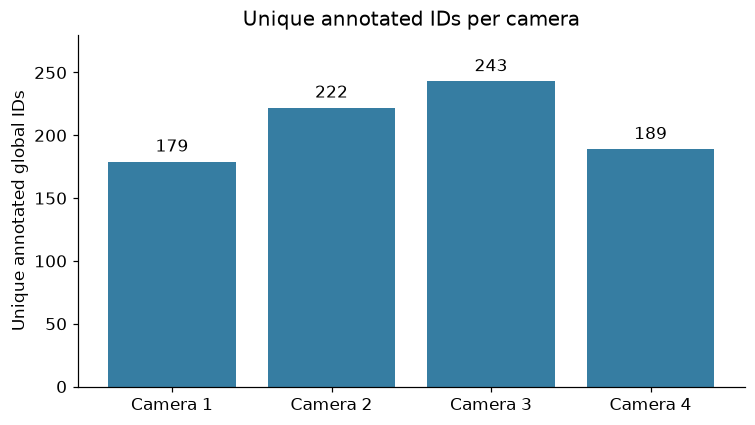

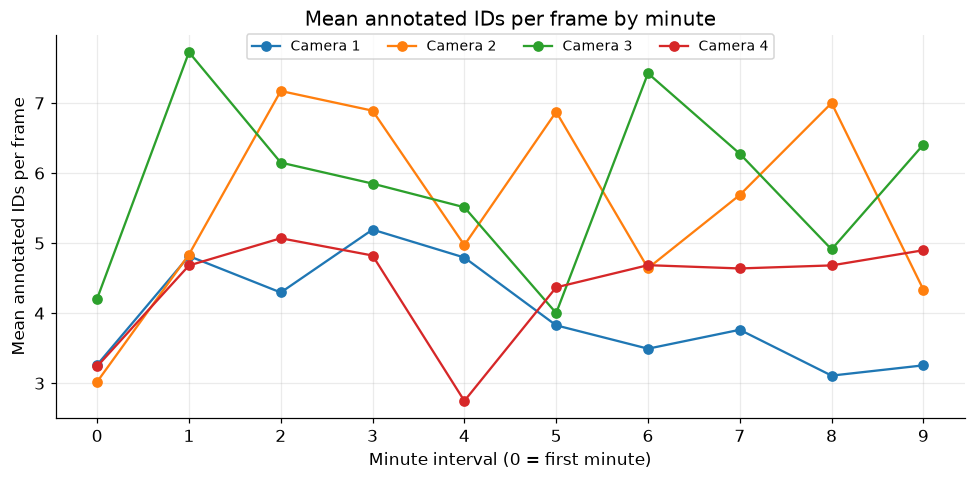

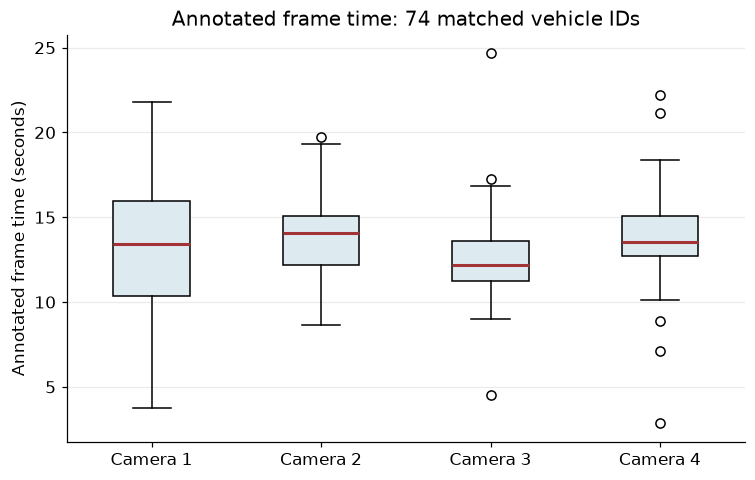

In [9]:
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.svg', metadata={'Date': None}, bbox_inches='tight')
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([f'Camera {c}' for c in CAMERAS], camera_summary.unique_annotated_ids,
              color='#367DA2')
ax.bar_label(bars, padding=4)
ax.set(title='Unique annotated IDs per camera', ylabel='Unique annotated global IDs', ylim=(0, 280))
save_figure(fig, 'unique_annotated_ids')

fig, ax = plt.subplots(figsize=(9, 4.5))
for cam in CAMERAS:
    ax.plot(mean_by_minute.index, mean_by_minute[cam], marker='o', label=f'Camera {cam}')
ax.set(title='Mean annotated IDs per frame by minute', xlabel='Minute interval (0 = first minute)',
       ylabel='Mean annotated IDs per frame', xticks=range(10))
ax.grid(alpha=.25)
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, 1.02), fontsize=9)
save_figure(fig, 'mean_annotated_ids_by_minute')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot([matched[cam].to_numpy() for cam in CAMERAS], patch_artist=True,
    boxprops={'facecolor': '#DDEBF1'}, medianprops={'color': '#A33337', 'linewidth': 2})
ax.set_xticks(range(1, 5), [f'Camera {c}' for c in CAMERAS])
ax.set(title=f'Annotated frame time: {len(matched)} matched vehicle IDs', ylabel='Annotated frame time (seconds)')
ax.grid(axis='y', alpha=.25)
save_figure(fig, 'matched_frame_times')

## 7. Generate the report and presentation from the computed results

The prose below uses live variables, so there are no hard-coded obsolete test results. Explanations of missing annotations remain explicitly unresolved.

In [10]:
report = f"""# RoundaboutHD: annotation coverage and camera comparison

This study examined vehicle annotations from four cameras monitoring different roundabouts. The objectives were to compare annotated observations, assess data quality, and explore whether annotated frame time differs across cameras for the same vehicles.

The multi-camera file contains {len(raw):,} rows and {raw.vehicle_id.nunique()} global vehicle IDs. Counting each camera–vehicle–frame key once gives {len(observations):,} distinct observations. Camera 3 has the highest annotated ID count ({camera_summary.loc[3, 'unique_annotated_ids']:.0f}), followed by cameras 2, 4, and 1. Its mean annotated count is {camera_summary.loc[3, 'mean_annotated_ids_per_frame']:.2f} per frame. These quantities describe included records, not verified totals of passing traffic.

The single-camera files contain {scope.sct_local_ids.sum():,} local IDs and {scope.sct_rows.sum():,} rows, matching the published SCT totals. Local IDs cannot be summed to count unique vehicles across cameras. Targeted source checks found four selected vehicle boxes in SCT and detection ground truth but without matching multi-camera boxes at an audit IoU threshold of 0.5. The association script supports selection of trajectories, but individual exclusion reasons remain unresolved.

For {len(matched)} IDs observed in all four cameras, annotated frame time was calculated as distinct annotated frames divided by {FPS} FPS. An exploratory Friedman test found evidence of camera differences (Q = {test.statistic:.4f}, p = {test.pvalue:.7f}), with a relatively small effect magnitude (Kendall's W = {test_results['kendalls_W']:.4f}). Possible dependence between vehicles and selection of the matched subset limit interpretation. The test does not establish causes or significant pairwise differences.

The audit identified {len(conflict_keys)} conflicting keys and annotation gaps. ID 553 has a {gap['missing_seconds']:.2f}-second gap whose cause remains unverified. Annotated frame time is not travel time or speed. The data supports analysis of included observations; complete traffic counting requires coverage validation. Differences from published global-ID totals remain unresolved.
"""
(REPORTS / 'final_report.md').write_text(report)
display(Markdown(report))

presentation = f"""# Presentation notes

## Approximately 60 seconds

I analyzed vehicle annotations from four cameras monitoring different roundabouts. I used Python to check the records, compare cameras, and plot changes over ten minutes.

The multi-camera file contains {raw.vehicle_id.nunique()} vehicle IDs. Camera 3 has the highest annotated count, but this does not necessarily mean it carries the most traffic.

For {len(matched)} vehicles observed by all four cameras, I compared the total time represented by annotated frames. An exploratory Friedman test found camera differences with a relatively small effect magnitude.

I also found conflicting records and gaps. Selected vehicles appeared in single-camera annotations but had no matching boxes in the multi-camera file. Therefore, the main result is a comparison of the included observations, with clear limitations on complete traffic counting and travel-time interpretation.

## Five likely questions

**1. Did you train a machine-learning model?**
No. I analyzed supplied annotations. The authors describe model-assisted annotation with manual correction and manual cross-camera association.

**2. Why does camera 3 have more IDs?**
It has more included annotated IDs. Traffic patterns, coverage, and annotation selection are possible explanations, but their contributions were not established.

**3. Why use the Friedman test?**
The same vehicles supply four related measurements. Friedman compares within-vehicle ranks without requiring normality. Vehicle independence may be imperfect, so the result is exploratory.

**4. Do missing boxes mean the dataset is bad?**
Not automatically. Different annotation sources include different records. We documented conflicts and selected missing matches, but did not estimate annotation accuracy or prove each exclusion's cause.

**5. Can this analysis estimate speed or total traffic?**
Not directly. Speed needs verified geometry and timing; total traffic needs validated coverage. Frame time is not journey duration, and the available world-coordinate columns contain placeholders.
"""
(REPORTS / 'presentation.md').write_text(presentation)
print('Report word count:', len(report.split()))

# RoundaboutHD: annotation coverage and camera comparison

This study examined vehicle annotations from four cameras monitoring different roundabouts. The objectives were to compare annotated observations, assess data quality, and explore whether annotated frame time differs across cameras for the same vehicles.

The multi-camera file contains 177,782 rows and 311 global vehicle IDs. Counting each camera–vehicle–frame key once gives 177,756 distinct observations. Camera 3 has the highest annotated ID count (243), followed by cameras 2, 4, and 1. Its mean annotated count is 5.85 per frame. These quantities describe included records, not verified totals of passing traffic.

The single-camera files contain 1,042 local IDs and 232,945 rows, matching the published SCT totals. Local IDs cannot be summed to count unique vehicles across cameras. Targeted source checks found four selected vehicle boxes in SCT and detection ground truth but without matching multi-camera boxes at an audit IoU threshold of 0.5. The association script supports selection of trajectories, but individual exclusion reasons remain unresolved.

For 74 IDs observed in all four cameras, annotated frame time was calculated as distinct annotated frames divided by 15 FPS. An exploratory Friedman test found evidence of camera differences (Q = 23.4268, p = 0.0000329), with a relatively small effect magnitude (Kendall's W = 0.1055). Possible dependence between vehicles and selection of the matched subset limit interpretation. The test does not establish causes or significant pairwise differences.

The audit identified 26 conflicting keys and annotation gaps. ID 553 has a 318.53-second gap whose cause remains unverified. Annotated frame time is not travel time or speed. The data supports analysis of included observations; complete traffic counting requires coverage validation. Differences from published global-ID totals remain unresolved.


Report word count: 277


## 8. Reproducibility checks and limits

These checks reconcile independent aggregations. They do not assert that all visible vehicles were annotated. No new video decoding or representative manual accuracy audit was performed in this final run; the targeted source audit uses vehicles identified in the earlier contact sheets.

In [11]:
assert scope.mc_rows.sum() == len(raw)
assert scope.mc_unique_observations.sum() == len(observations)
assert int(frame_counts.to_numpy().sum()) == len(observations)
assert int(tracks.observed_frames.sum()) == len(observations)
assert np.allclose(camera_summary.mean_annotated_ids_per_frame, mean_by_minute.mean())
assert coverage.sum() == raw.vehicle_id.nunique()
assert int((coverage.index.to_numpy() * coverage.to_numpy()).sum()) == len(tracks)
assert len(matched) == int(coverage.loc[4])
assert len(mean_by_minute) == 10
assert matched.notna().all().all()
versions = {name: importlib.metadata.version(name) for name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'openpyxl']}
versions['python'] = platform.python_version()
(TABLES / 'environment.json').write_text(json.dumps(versions, indent=2))
print('All aggregation consistency checks passed.')
print(f'Reports, tables, and three figures saved under {ROOT}')

All aggregation consistency checks passed.
Reports, tables, and three figures saved under /workspace/work/roundabouthd/repo
